[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch57_LabCh57_Q_Learning_Grid_World.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 57: Reinforcement Learning: Learning from Reward** (Part XII: Other Shapes of Data).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=57](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=57)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch57 - Q-learning in a grid world
## A robot, a maze with no map, a lump of cheese, and a table of 120 numbers

This lab goes with **Chapter 57** of *The Why Book of Deep Learning, Part 2*.

There is no neural network in this lab, no Keras and no data set. Reinforcement learning has no data set:
the learner makes its own data by acting. Everything here is NumPy, and the thing that learns is a table
with one row per cell of a small maze and one column per move. Chapter 58 replaces that table with a
network. First you should watch the table work, and watch it fail.

| The miniature | value |
|---|---|
| world | a 5 by 6 grid: 30 cells, 7 of them walls, one pit, one goal (the cheese) |
| actions | 4: up, right, down, left |
| rewards | -1 for every step, +10 for reaching the cheese, -10 for falling in the pit |
| what is learnt | a Q-table of 30 x 4 = 120 numbers |
| defaults | learning rate 0.1, discount 0.9, epsilon 0.1, 500 episodes |
| second world | the cliff walk, 4 by 12, for Q-learning against SARSA |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write an environment with `reset()` and `step(action)` and run the agent-environment loop | Steps 2 and 3 |
| Compute a return at any discount, and say how far ahead a discount can see | Step 4 |
| Do a Q-learning update by hand and explain the surprise that drives it | Step 5 |
| Explain the explore-or-exploit dilemma on a bandit with five arms | Step 6 |
| Train a Q-table with epsilon-greedy exploration and read it as values and as a policy | Steps 7 to 10 |
| Predict what epsilon, the starting values, the discount and the learning rate each change | Steps 11 to 13 |
| Explain why Q-learning walks the cliff edge and SARSA does not | Step 14 |
| Spot a reward that will be exploited before the agent finds it for you | Step 15 |
| Count why a table cannot scale | Step 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about one minute on a laptop CPU. No GPU is needed and nothing is downloaded.

> **Honest scale:** this is a miniature. A world of 30 cells can be solved exactly with pencil and paper,
> and Step 9 does so. The numbers printed here describe this toy. What carries over to large problems is
> the loop, the update rule, the dilemmas (explore or exploit, near or far, cautious or bold) and the
> habit of running several seeds before believing a comparison.

---
## Step 1 - Imports and one seed

In [1]:
import time, random
import numpy as np
import matplotlib.pyplot as plt

SEED = 57
np.set_printoptions(precision=2, suppress=True, linewidth=110)
T_START = time.time()
print("NumPy", np.__version__)

NumPy 2.4.6


## Step 2 - The world, as a small class

The **environment** is everything that is not the learner. Ours is drawn as text: `S` is the start, `G` the
goal, `P` a pit, `#` a wall and `.` a free cell. The learner will never see this drawing. All it ever gets
is a **state** (the number of the cell it stands on, counted along the rows from 0) and, after each move,
a **reward**.

The class has two methods that matter, and Chapter 58 uses the same two:

- `reset()` puts the agent on the start and returns the state;
- `step(action)` makes one move and returns `(state, reward, done)`.

Walking into a wall or off the edge leaves you where you were, and still costs a step. If `slip` is above
zero, that fraction of moves goes sideways instead (half to each side): an icy floor.

**Predict before you run:** the start is the bottom-left cell and the goal is in the right-hand column.
Trace the shortest route with your finger. How many steps is it, and what do its rewards add up to?

In [2]:
ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]       # up, right, down, left, as (row change, column change)
NAMES = ["up", "right", "down", "left"]
ARROWS = "↑→↓←"

class GridWorld:
    """A grid of cells. reset() -> state.  step(action) -> (state, reward, done).

    layout: list of strings. S start, G goal (ends the episode), P pit (ends the episode), # wall, . free,
            c a crumb (ends the episode, small reward), o a coin (paid each time the agent steps onto it).
    A state is the cell number, row * cols + col. Actions are 0 up, 1 right, 2 down, 3 left.
    """
    def __init__(self, layout, step_reward=-1.0, goal_reward=10.0, pit_reward=-10.0,
                 crumb_reward=1.0, coin_reward=3.0, slip=0.0, seed=0):
        self.layout = [str(row) for row in layout]
        self.rows, self.cols = len(self.layout), len(self.layout[0])
        self.n_states, self.n_actions = self.rows * self.cols, 4
        self.step_reward, self.goal_reward, self.pit_reward = step_reward, goal_reward, pit_reward
        self.crumb_reward, self.coin_reward = crumb_reward, coin_reward
        self.slip = slip
        self.rng = np.random.default_rng(seed)       # the world's own dice (used only when slip > 0)
        self.start = "".join(self.layout).index("S")
        self.state = self.start

    def cell(self, s):
        return self.layout[s // self.cols][s % self.cols]

    def move(self, s, a):
        """The rule of movement: where action a leads from cell s when nothing slips."""
        r, c = divmod(s, self.cols)
        r2, c2 = r + ACTIONS[a][0], c + ACTIONS[a][1]
        if not (0 <= r2 < self.rows and 0 <= c2 < self.cols) or self.layout[r2][c2] == "#":
            return s                                  # wall or edge: stay put
        return r2 * self.cols + c2

    def outcome(self, s, s2):
        """The rule of reward: what arriving in s2 from s pays, and whether the episode is over."""
        kind = self.cell(s2)
        if kind == "G": return self.goal_reward, True
        if kind == "P": return self.pit_reward, True
        if kind == "c": return self.crumb_reward, True
        if kind == "o" and s2 != s: return self.step_reward + self.coin_reward, False
        return self.step_reward, False

    def reset(self):
        self.state = self.start
        return self.state

    def step(self, action):
        if self.slip > 0 and self.rng.random() < self.slip:          # the floor is icy: slide sideways
            action = (action + (1 if self.rng.random() < 0.5 else 3)) % 4
        s2 = self.move(self.state, action)
        reward, done = self.outcome(self.state, s2)
        self.state = s2
        return s2, reward, done

    def model(self, s, a):
        """The rules written out as [(probability, next state, reward, done)]. Only the planner of Step 9 reads this."""
        out = []
        for p, a2 in ((1 - self.slip, a), (self.slip / 2, (a + 1) % 4), (self.slip / 2, (a + 3) % 4)):
            if p > 0:
                s2 = self.move(s, a2)
                out.append((p, s2) + self.outcome(s, s2))
        return out

def draw_map(env, Q=None):
    """Print the world. With a Q-table, print the best action in every free cell instead."""
    for r in range(env.rows):
        line = ""
        for c in range(env.cols):
            s = r * env.cols + c
            kind = env.cell(s)
            line += "  " + (kind if (Q is None or kind in "#GPc") else ARROWS[int(np.argmax(Q[s]))])
        print(line)

MAZE = ["......",
        ".####.",
        "...P.G",
        ".#...#",
        "S..#.."]
env = GridWorld(MAZE)
draw_map(env)
print(f"\n{env.rows} x {env.cols} = {env.n_states} states, {env.n_actions} actions, "
      f"Q-table of {env.n_states * env.n_actions} numbers")
print("walls:", "".join(MAZE).count("#"), "| start is state", env.start,
      "| goal is state", "".join(MAZE).index("G"), "| pit is state", "".join(MAZE).index("P"))

s = env.reset()
print("\nreset() ->", s)
for a in (1, 3, 3):                                   # right, left, left (the last one bumps into the edge)
    s, r, done = env.step(a)
    print(f"step({a})  [{NAMES[a]:5s}] -> state {s}, reward {r}, done {done}")

  .  .  .  .  .  .
  .  #  #  #  #  .
  .  .  .  P  .  G
  .  #  .  .  .  #
  S  .  .  #  .  .

5 x 6 = 30 states, 4 actions, Q-table of 120 numbers
walls: 7 | start is state 24 | goal is state 17 | pit is state 15

reset() -> 24
step(1)  [right] -> state 25, reward -1.0, done False
step(3)  [left ] -> state 24, reward -1.0, done False
step(3)  [left ] -> state 24, reward -1.0, done False


## Step 3 - The loop, with an agent that knows nothing

The whole of reinforcement learning happens inside one loop: the agent sees a state, picks an action, and
the environment answers with a new state and a reward. One pass from `reset()` to `done` is an **episode**.
A **policy** is the rule that picks the action. The simplest policy of all ignores the state and rolls a die.

We stop an episode after 200 steps if it has not ended by then. That limit is ours, not the world's.

**Predict before you run:** an agent that moves at random for up to 200 steps. Out of 1,000 episodes, how
many end at the cheese, how many in the pit, and how many run out of time?

In [3]:
def run_episode(env, policy, max_steps=200, trace=None):
    """Run one episode with policy(state) -> action. Returns (sum of rewards, steps, how it ended)."""
    s = env.reset()
    total = 0.0
    for t in range(1, max_steps + 1):
        s, r, done = env.step(policy(s))
        total += r
        if trace is not None: trace.append(s)
        if done:
            return total, t, {"G": "goal", "P": "pit", "c": "crumb"}[env.cell(s)]
    return total, max_steps, "time"

rng = np.random.default_rng(SEED)
random_policy = lambda s: int(rng.integers(4))
results = [run_episode(env, random_policy) for _ in range(1000)]
ends = [e for _, _, e in results]
print("1,000 episodes of a random agent")
for kind in ("goal", "pit", "time"):
    print(f"  ended at {kind:5s}: {ends.count(kind):4d}")
print(f"  mean reward per episode: {np.mean([t for t, _, _ in results]):7.2f}")
print(f"  mean steps per episode : {np.mean([n for _, n, _ in results]):7.2f}")
RANDOM_REWARD = float(np.mean([t for t, _, _ in results]))

1,000 episodes of a random agent
  ended at goal :  173
  ended at pit  :  791
  ended at time :   36
  mean reward per episode:  -65.97
  mean steps per episode :   60.75


### Why we see this

The pit sits in the middle of the map and the cheese in a corner, so a random walk usually finds the pit
first. Notice what the agent was told after each of those episodes: a list of numbers, nearly all of them
-1, ending in +10 or -10. Nobody said which move was the mistake. That is the difference from every lab
before this one: **a reward is a score for what you did, not the answer you should have given.**

---
## Step 4 - Return and discount: adding up a path

The agent's aim is not the next reward. It is the **return**: all the rewards from now to the end of the
episode, added up, with later ones counted for less. The **discount factor** (gamma) is how much less:
a reward `k` steps away is multiplied by `gamma ** k`.

Two paths by hand. The **short** one goes along the bottom, past the pit, in 7 steps. The **long** one
climbs the left wall, crosses the top row and comes down on the cheese in 11 steps.

A rule of thumb: a discount of gamma looks about `1 / (1 - gamma)` steps ahead. We call that its horizon.

**Predict before you run:** at a discount of 0.5, is the return of the short path (six steps at -1, then
+10) positive or negative? At 0.9? What is the +10 worth, seen from the start, at each discount?

In [4]:
SHORT = [1, 1, 0, 1, 1, 0, 1]                          # right right up right right up right
LONG = [0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2]               # up x 4, right x 5, down x 2

def rewards_along(env, actions):
    env.reset()
    out = []
    for a in actions:
        _, r, done = env.step(a)
        out.append(r)
    assert done, "this path does not end the episode"
    return out

def discounted(rewards, gamma):
    return sum(r * gamma ** k for k, r in enumerate(rewards))

r_short, r_long = rewards_along(env, SHORT), rewards_along(env, LONG)
print("short path rewards:", r_short)
print("long path rewards :", r_long)
print()
print(f"{'discount':>8s} {'horizon 1/(1-g)':>16s} {'short path':>11s} {'long path':>10s} {'the +10 seen from the start':>29s}")
RET = {}
for g in (0.5, 0.9, 0.99, 1.0):
    hz = "no limit" if g == 1 else f"{1 / (1 - g):.0f} steps"
    RET[g] = (discounted(r_short, g), discounted(r_long, g))
    print(f"{g:8.2f} {hz:>16s} {RET[g][0]:11.3f} {RET[g][1]:10.3f} {10 * g ** (len(r_short) - 1):29.3f}")

short path rewards: [-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, 10.0]
long path rewards : [-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, 10.0]

discount  horizon 1/(1-g)  short path  long path   the +10 seen from the start
    0.50          2 steps      -1.812     -1.988                         0.156
    0.90         10 steps       0.629     -3.026                         5.314
    0.99        100 steps       3.563     -0.518                         9.415
    1.00         no limit       4.000      0.000                        10.000


### Why we see this

The same seven steps are worth -1.81, +0.63 or +3.56 depending on one number. At a discount of 0.5 the
cheese is six halvings away: 10 x 0.5^6 = 0.16. An agent with that discount can hardly tell the path to
the cheese from a walk to nowhere, because its horizon is 2 steps and the cheese is 7 away. At 0.99 the
cheese keeps 94% of its worth and the six step costs are a small tax.

The discount is not a property of the world. It is a statement of how patient you want the agent to be,
and you choose it.

---
## Step 5 - The Q-table, and three passes of updates by hand

The agent will keep a table `Q` with one row per state and one column per action. `Q[s, a]` is its current
guess at the return it will get if it takes action `a` in state `s` and behaves as well as it can afterwards.
The table starts as all zeros: the agent knows nothing.

**The Q-learning update.** After one step from `s` by action `a`, with reward `r`, landing in `s2`:

1. `target = r + gamma * max(Q[s2])` (or `target = r` if the episode ended): a better guess, made of one
   real reward plus the table's own opinion of where we landed;
2. `surprise = target - Q[s, a]` (the temporal-difference error);
3. `Q[s, a] += alpha * surprise`: move the entry a fraction `alpha` of the way.

We walk the short path three times and print every update. To make the numbers easy to follow by eye this
step uses a learning rate of 0.5 (the lab's default is 0.1).

**Predict before you run:** after the first walk, which entries of the table know anything about the
cheese? After the second? How many walks before the start cell hears of it?

In [5]:
GAMMA = 0.9

def q_update(Q, s, a, r, s2, done, alpha, gamma, say=False):
    old = Q[s, a]
    best_next = 0.0 if done else Q[s2].max()
    target = r + gamma * best_next
    surprise = target - old
    Q[s, a] = old + alpha * surprise
    if say:
        where = f"({s // env.cols},{s % env.cols}) {ARROWS[a]}"
        how = f"{r:+.0f}" if done else f"{r:+.0f} + {gamma} x {best_next:5.2f}"
        print(f"  {where}  old {old:6.3f} | target = {how:>17s} = {target:6.3f} | surprise {surprise:+7.3f} | new {Q[s, a]:6.3f}")
    return surprise

Q_hand = np.zeros((env.n_states, 4))
for walk in (1, 2, 3):
    print(f"walk {walk} along the short path (alpha = 0.5, gamma = {GAMMA})")
    s = env.reset()
    for a in SHORT:
        s2, r, done = env.step(a)
        q_update(Q_hand, s, a, r, s2, done, alpha=0.5, gamma=GAMMA, say=True)
        s = s2
    print()

# how many walks until the entry at the start turns positive?
Q_count = np.zeros((env.n_states, 4)); walks = 0
while Q_count[env.start, SHORT[0]] <= 0:
    walks += 1
    s = env.reset()
    for a in SHORT:
        s2, r, done = env.step(a)
        q_update(Q_count, s, a, r, s2, done, alpha=0.5, gamma=GAMMA)
        s = s2
print(f"walks before the start cell's entry is above zero: {walks}  (it is now {Q_count[env.start, SHORT[0]]:.3f}; "
      f"the true value is {RET[0.9][0]:.3f})")

walk 1 along the short path (alpha = 0.5, gamma = 0.9)
  (4,0) →  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (4,1) →  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (4,2) ↑  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (3,2) →  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (3,3) →  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (3,4) ↑  old  0.000 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -1.000 | new -0.500
  (2,4) →  old  0.000 | target =               +10 = 10.000 | surprise +10.000 | new  5.000

walk 2 along the short path (alpha = 0.5, gamma = 0.9)
  (4,0) →  old -0.500 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -0.500 | new -0.750
  (4,1) →  old -0.500 | target =  -1 + 0.9 x  0.00 = -1.000 | surprise  -0.500 | new -0.750
  (4,2) ↑  old -0.500 | target =  -1 + 0.9 x  0.00 = -1.000 |

### Why we see this

On the first walk only the very last update saw the cheese: the entry for "right, from the cell beside the
goal" jumped from 0 to 5. Every earlier update saw a reward of -1 and a table of zeros, so it learnt
nothing but the cost of a step. On the second walk the entry one cell earlier met a surprise of +4: it
expected -0.5, and found a reward of -1 followed by a cell the table now says is worth 5. On the third
walk the news reached one cell further back.

That is how the table answers the hardest question in the subject, the **credit assignment problem**:
which earlier move earned this reward? It does not trace the reward back in one go. Each entry learns
from its neighbour's entry, so the news travels backwards one cell per visit. The price is that early
estimates are built on guesses about guesses. (Building an estimate out of another estimate is called
bootstrapping.)

---
## Step 6 - The smallest dilemma: a bandit with five arms

Before letting the agent loose, one question has to be faced. The table only improves for the actions the
agent actually tries. If it always takes the action that looks best so far, it never finds out whether a
different one is better. If it keeps trying everything, it never cashes in on what it knows.

The smallest version has no states at all: five slot-machine arms, each paying a noisy reward round a
hidden mean. You have 1,000 pulls. **Greedy** always pulls the arm with the best average so far.
**Epsilon-greedy** does the same, except that a fraction epsilon of the time it pulls an arm at random.
The fourth player is greedy too, but starts by believing every arm pays 5: an **optimistic start**.

**Predict before you run:** in what fraction of 2,000 games does plain greedy end up on the best arm?
Which player collects the most reward over 1,000 pulls: epsilon 0.01 or epsilon 0.1?

In [6]:
ARM_MEANS = np.array([0.2, 0.5, 0.4, 0.8, 0.6])        # hidden from the player; arm 3 is the best
PULLS, GAMES = 1000, 2000

def play_bandit(eps, start=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    est = np.full((GAMES, 5), start)                   # each game's running average for each arm
    n = np.zeros((GAMES, 5))
    total = np.zeros(GAMES); late_best = np.zeros(GAMES)
    rows = np.arange(GAMES)
    for t in range(PULLS):
        arm = np.argmax(est + 1e-9 * rng.random((GAMES, 5)), axis=1)        # greedy, ties broken at random
        explore = rng.random(GAMES) < eps
        arm = np.where(explore, rng.integers(5, size=GAMES), arm)
        reward = ARM_MEANS[arm] + rng.normal(0, 1, GAMES)
        n[rows, arm] += 1
        est[rows, arm] += (reward - est[rows, arm]) / n[rows, arm]         # running average
        total += reward
        if t >= PULLS - 100: late_best += (arm == 3)
    return total.mean() / PULLS, (np.argmax(n, axis=1) == 3).mean(), late_best.mean() / 100

print(f"best possible mean reward per pull: {ARM_MEANS.max():.2f};  pulling at random: {ARM_MEANS.mean():.2f}\n")
print(f"{'player':32s} {'reward per pull':>15s} {'games whose favourite arm is the best':>38s}")
for name, eps, start in [("greedy (epsilon 0)", 0.0, 0.0), ("epsilon 0.01", 0.01, 0.0), ("epsilon 0.1", 0.1, 0.0),
                         ("greedy, optimistic start of 5", 0.0, 5.0)]:
    per_pull, fav, late = play_bandit(eps, start)
    print(f"{name:32s} {per_pull:15.3f} {100 * fav:37.1f}%")

best possible mean reward per pull: 0.80;  pulling at random: 0.50

player                           reward per pull  games whose favourite arm is the best


greedy (epsilon 0)                         0.568                                  30.8%

epsilon 0.01                               0.641                                  48.9%


epsilon 0.1                                0.711                                  80.8%


greedy, optimistic start of 5              0.656                                  50.1%

### Why we see this

Plain greedy locks on to whichever arm happened to pay well early. A bad first pull from the best arm is
enough for it never to be tried again, and the player never learns what it missed: **you only learn about
what you try.** A little random exploration repairs that, at a price: the exploring pulls are mostly
wasted on arms already known to be poor. Over these 1,000 pulls the heavier explorer comes out ahead. Over
a much longer game its tax would never stop, which is why epsilon is usually reduced as learning goes on.

The optimistic player explores without rolling any dice. Every arm it has not tried looks wonderful, every
arm it tries disappoints, so it tries them all before settling. Keep that trick in mind for Step 11.

---
## Step 7 - Q-learning with epsilon-greedy exploration

Now the full algorithm, which is Step 5's update inside Step 3's loop, with Step 6's way of choosing:
with probability epsilon take a random action, otherwise take the best one in the table (ties broken at
random, which matters while the table is still all zeros).

The function returns the table and a log with the reward and the number of steps of every episode.
While it learns, the table is a plain Python list of lists (for one-number-at-a-time updates that is
several times faster than a NumPy array); it is handed back as an array of shape `(30, 4)`.

If the 200-step limit is reached the episode is cut short and nothing more: the table is not told that
anything ended, because nothing in the world did.

**Predict before you run:** the first episode starts from a table of zeros, so it is a random walk. Roughly
what reward does it collect? By the last hundred episodes the agent still explores one move in ten. Will
its average reward reach the +4 of the short path?

In [7]:
def pick(row, eps, rng):
    """Epsilon-greedy: a random action with probability eps, otherwise the best in the row (ties at random)."""
    if rng.random() < eps:
        return rng.randrange(4)
    top = max(row)
    return rng.choice([a for a in range(4) if row[a] == top])

def q_learning(env, episodes=500, alpha=0.1, gamma=0.9, eps=0.1, eps_end=None, q0=0.0,
               seed=0, max_steps=200, watch=None):
    """Tabular Q-learning. eps_end: if given, epsilon slides in a straight line from eps to eps_end.
    q0: the value the table starts at. watch: a state whose best value is logged after every episode."""
    rng = random.Random(seed)                          # the agent's own dice
    Q = [[q0] * env.n_actions for _ in range(env.n_states)]
    log = {"reward": np.zeros(episodes), "steps": np.zeros(episodes, dtype=int), "watch": np.zeros(episodes)}
    for ep in range(episodes):
        e = eps if eps_end is None else eps + (eps_end - eps) * ep / (episodes - 1)
        s = env.reset()
        total = 0.0
        for t in range(1, max_steps + 1):
            a = pick(Q[s], e, rng)                                   # choose
            s2, r, done = env.step(a)                                # act
            target = r if done else r + gamma * max(Q[s2])          #   the best the table knows of s2
            Q[s][a] += alpha * (target - Q[s][a])                    # learn
            total += r
            s = s2
            if done: break
        log["reward"][ep], log["steps"][ep] = total, t
        if watch is not None: log["watch"][ep] = max(Q[watch])
    return np.array(Q), log

t0 = time.time()
Q, log = q_learning(env, seed=SEED)
print(f"500 episodes, {log['steps'].sum():,} steps of experience, {time.time() - t0:.2f} s")
print("reward of the first 10 episodes:", log["reward"][:10].astype(int))
print("reward of the last 10 episodes :", log["reward"][-10:].astype(int))
print(f"mean reward, episodes 1 to 20: {log['reward'][:20].mean():7.2f}   (a random agent: {RANDOM_REWARD:.2f})")
print(f"mean reward, last 100        : {log['reward'][-100:].mean():7.2f}   (the short path pays +4)")

500 episodes, 5,061 steps of experience, 0.01 s
reward of the first 10 episodes: [ -43  -70  -33 -140  -60  -97  -89  -11  -50   -3]
reward of the last 10 episodes : [1 3 4 1 4 2 4 4 4 4]
mean reward, episodes 1 to 20:  -46.35   (a random agent: -65.97)
mean reward, last 100        :    2.16   (the short path pays +4)


## Step 8 - Read the table two ways: values and a policy

The table holds what was learnt in two forms at once. The largest number in each row is the **value** of
that cell: how good it is to be there. The position of the largest number is the **policy**: what to do
there. We draw the first as a heat map and the second as arrows, then let the agent walk its policy with
exploration switched off.

**Predict before you run:** which cell will have the highest value? Will the cells along the top row,
far from the route, hold sensible values?

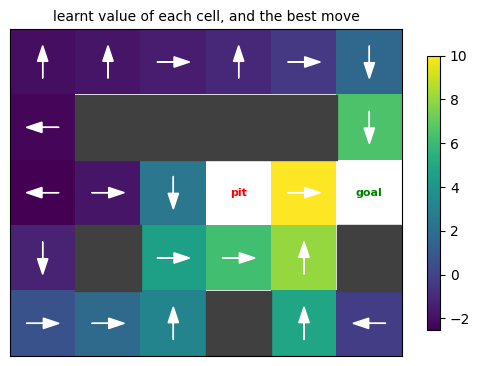

the policy, as arrows:
  ↑  ↑  →  ↑  →  ↓
  ←  #  #  #  #  ↓
  ←  →  ↓  P  →  G
  ↓  #  →  →  ↑  #
  →  →  ↑  #  ↑  ←

value of each cell (the largest entry of its row):
[[-2.06 -1.81 -1.55 -1.13 -0.46  1.69]
 [-2.3   0.    0.    0.    0.    6.51]
 [-2.51 -1.8   2.46  0.   10.    0.  ]
 [-1.3   0.    4.58  6.2   8.    0.  ]
 [ 0.63  1.81  3.12  0.    4.86 -0.26]]

the four entries for some cells on the route      up   right    down    left
  state 24 = cell (4,0)                       -2.92    0.63   -1.33   -1.63
  state 25 = cell (4,1)                       -0.62    1.81   -0.60   -1.23
  state 26 = cell (4,2)                        3.12    1.17    1.05   -0.34
  state 20 = cell (3,2)                        0.12    4.58    0.47    2.27
  state 21 = cell (3,3)                       -8.78    6.20    3.76    1.58
  state 22 = cell (3,4)                        8.00    2.75    1.57    2.99
  state 16 = cell (2,4)                        5.93   10.00    4.62   -7.46

exploration off: reward

In [8]:
def greedy(Q):
    return lambda s: int(np.argmax(Q[s]))

def plot_table(env, Q, ax, title):
    V = Q.max(axis=1).reshape(env.rows, env.cols).copy()
    for s in range(env.n_states):
        if env.cell(s) in "#GPc": V[s // env.cols, s % env.cols] = np.nan
    im = ax.imshow(V, cmap="viridis")
    for s in range(env.n_states):
        r, c = divmod(s, env.cols); kind = env.cell(s)
        if kind == "#": ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="0.25"))
        elif kind in "GPc": ax.text(c, r, {"G": "goal", "P": "pit", "c": "crumb"}[kind], ha="center", va="center", fontsize=8,
                                    color={"G": "green", "P": "red", "c": "orange"}[kind], weight="bold")
        else:
            dr, dc = ACTIONS[int(np.argmax(Q[s]))]
            ax.arrow(c - .25 * dc, r - .25 * dr, .5 * dc, .5 * dr, head_width=.16, color="white", length_includes_head=True)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=10)
    return im

fig, ax = plt.subplots(figsize=(5.2, 3.8))
plt.colorbar(plot_table(env, Q, ax, "learnt value of each cell, and the best move"), shrink=0.8)
plt.tight_layout(); plt.show()

print("the policy, as arrows:"); draw_map(env, Q)
print("\nvalue of each cell (the largest entry of its row):")
print(Q.max(axis=1).reshape(env.rows, env.cols))
print("\nthe four entries for some cells on the route      up   right    down    left")
for s in (24, 25, 26, 20, 21, 22, 16):
    print(f"  state {s:2d} = cell ({s // env.cols},{s % env.cols})                     " + " ".join(f"{q:7.2f}" for q in Q[s]))
trace = []
total, steps, end = run_episode(env, greedy(Q), max_steps=100, trace=trace)
print(f"\nexploration off: reward {total:+.0f} in {steps} steps, ended at the {end}; cells visited: {[env.start] + trace}")

### Why we see this

The values rise towards the cheese like a hillside, and the policy is "walk uphill". The agent has no
map and no plan: it has a number for every cell and a habit of preferring the bigger number.

Look at the top row, far from the route: are its arrows all sensible? The table is sharp along the route
the agent uses and vague elsewhere, because an entry is only corrected when the agent passes through it.
A Q-table is not a map of the world. It is a record of where this agent has been. Step 9 measures how
vague.

---
## Step 9 - What if we had been given the rules? Planning

Q-learning is **model-free**: it never looked at the rules of the maze, only at what happened to it. If
you are given the rules (here, `env.model`), you do not need to act at all. You can compute the exact
value of every state-action pair by repeating one line until the numbers stop changing: *the value of a
move is its reward plus the discounted value of the best move from where it lands.* That is the
**Bellman equation** used as an update, and the method is called value iteration. It is **model-based**.

**Predict before you run:** how many sweeps over the table will the planner need before nothing changes?
(Think of Step 5: how far does news travel per sweep?) How close did 500 episodes of experience get to
the exact answer on the route, and off it?

In [9]:
def plan(env, gamma=0.9, tol=1e-9):
    """Value iteration: the exact Q-table from the rules alone. Returns (Q, number of sweeps)."""
    Q = np.zeros((env.n_states, env.n_actions)); sweeps = 0
    while True:
        Q_new = np.zeros_like(Q)
        for s in range(env.n_states):
            if env.cell(s) in "#GPc": continue
            for a in range(env.n_actions):
                Q_new[s, a] = sum(p * (r if done else r + gamma * Q[s2].max()) for p, s2, r, done in env.model(s, a))
        sweeps += 1
        if np.abs(Q_new - Q).max() < tol:
            return Q_new, sweeps
        Q = Q_new

Q_star, sweeps = plan(env, GAMMA)
print(f"planner: {sweeps} sweeps of {env.n_states} x {env.n_actions} entries, no experience at all")
print("exact policy:"); draw_map(env, Q_star)
print(f"\nexact value at the start: {Q_star[env.start].max():.3f}   (Step 4's hand sum: {RET[0.9][0]:.3f})")
print(f"learnt value at the start: {Q[env.start].max():.3f}")
route = [(24, 1), (25, 1), (26, 0), (20, 1), (21, 1), (22, 0), (16, 1)]        # (state, action) along the short path
err_route = max(abs(Q[s, a] - Q_star[s, a]) for s, a in route)
free = [s for s in range(env.n_states) if env.cell(s) not in "#GPc"]
err_all = np.abs(Q[free] - Q_star[free])
print(f"largest error of the learnt table on the route : {err_route:.3f}")
print(f"largest error anywhere                          : {err_all.max():.3f}   (mean {err_all.mean():.3f})")
agree = sum(Q_star[s, int(np.argmax(Q[s]))] >= Q_star[s].max() - 1e-9 for s in free)
print(f"cells where the learnt best move is a truly best move: {agree} of {len(free)}")

planner: 10 sweeps of 30 x 4 entries, no experience at all
exact policy:
  →  →  →  →  →  ↓
  ↑  #  #  #  #  ↓
  →  →  ↓  P  →  G
  ↑  #  →  →  ↑  #
  →  →  ↑  #  ↑  ←

exact value at the start: 0.629   (Step 4's hand sum: 0.629)
learnt value at the start: 0.629
largest error of the learnt table on the route : 0.000
largest error anywhere                          : 8.100   (mean 2.680)
cells where the learnt best move is a truly best move: 16 of 21


### Why we see this

With the rules in hand, a few sweeps of arithmetic give the exact table. Experience took thousands of
steps to get the route right and still left the rest of the table rough. So why learn from experience at
all? Because the planner needed `env.model`: a complete, correct list of what every action does in every
state. For a maze you can write that list. For a robot arm, a market or a patient you cannot, and a
learnt model is wrong in ways that a planner will happily exploit. Model-free methods pay in experience
for not needing the rules.

---
## Step 10 - Reward per episode, over ten seeds

One run is one story. The agent's dice decide which walls it bumps into first, so two runs with different
seeds learn at different speeds. From here on every claim is made over ten seeds, with the spread.

We also measure each trained table twice: the reward it collected **while learning** (exploration on) and
the reward of its policy with **exploration off**.

**Predict before you run:** the agent explores one move in ten, for ever. How far below the +4 of the
short path will its reward stay during training? Is that gap a fault in what it learnt?

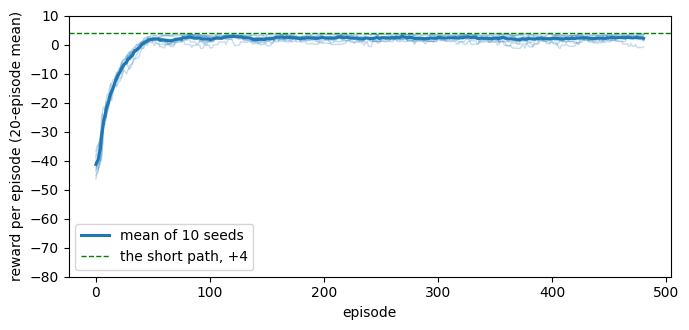

    episodes  mean reward  spread over seeds (std)
     1 to 20       -41.31                     3.11
   21 to 100        -1.60                     0.69
  101 to 200         2.16                     0.52
  401 to 500         2.18                     0.65

first episode at which the 20-episode mean is above zero, per seed: [57, 59, 66, 60, 59, 60, 61, 62, 61, 56]
reward with exploration off, per seed: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
reward with exploration on (last 100 episodes): 2.18


In [10]:
SEEDS = range(10)

def smooth(x, k=20):
    return np.convolve(x, np.ones(k) / k, mode="valid")

runs = [q_learning(env, seed=sd) for sd in SEEDS]
R = np.array([lg["reward"] for _, lg in runs])                      # (10 seeds, 500 episodes)
checks = [run_episode(env, greedy(Qs), max_steps=100)[0] for Qs, _ in runs]

fig, ax = plt.subplots(figsize=(7, 3.4))
for row in R: ax.plot(smooth(row), color="tab:blue", alpha=0.25, lw=1)
ax.plot(smooth(R.mean(axis=0)), color="tab:blue", lw=2.2, label="mean of 10 seeds")
ax.axhline(4, color="green", ls="--", lw=1, label="the short path, +4")
ax.set_xlabel("episode"); ax.set_ylabel("reward per episode (20-episode mean)"); ax.set_ylim(-80, 10); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'episodes':>12s} {'mean reward':>12s} {'spread over seeds (std)':>24s}")
for name, sl in (("1 to 20", slice(0, 20)), ("21 to 100", slice(20, 100)), ("101 to 200", slice(100, 200)), ("401 to 500", slice(400, 500))):
    per_seed = R[:, sl].mean(axis=1)
    print(f"{name:>12s} {per_seed.mean():12.2f} {per_seed.std():24.2f}")
first_ok = [int(np.argmax(smooth(row) > 0)) + 20 for row in R]
print("\nfirst episode at which the 20-episode mean is above zero, per seed:", first_ok)
print("reward with exploration off, per seed:", [int(c) for c in checks])
print(f"reward with exploration on (last 100 episodes): {R[:, -100:].mean():.2f}")

### Why we see this

Every seed learns the short path: with exploration off, all ten collect +4. During training the same
tables collect less, because one move in ten is random and the route passes beside the pit. That gap is
the cost of exploring, not a flaw in the table. **Report the two numbers separately, and say which one
you are reporting.** An agent judged with its exploration still on looks worse than it is.

In this small, quiet world the ten seeds tell nearly the same story: the spread is small and they all
turn the corner within a few episodes of each other. Enjoy it while it lasts. Steps 13 and 14 add noise
and danger, and there the seeds disagree enough to change a conclusion.

---
## Step 11 - Vary epsilon, and the values the table starts with

Epsilon sets how often the agent tries something other than its current favourite. We try six settings,
one of which slides from 1 down to 0 over the run (a **decaying** epsilon), and report three things:
reward over the whole of training, reward over the last 100 episodes, and how many of the ten tables
give the best route with exploration off.

**Predict before you run:** epsilon = 0 never explores on purpose. Does it fail? Epsilon = 1 never does
anything but explore. Does it learn the route?

In [11]:
def sweep(env, settings, label="setting", check_steps=100, **common):
    print(f"{label:30s} {'all 500 episodes':>17s} {'last 100':>10s} {'best route found (of 10)':>26s}")
    out = {}
    for name, kw in settings:
        rs = [q_learning(env, seed=sd, **common, **kw) for sd in SEEDS]
        allr = np.mean([lg["reward"].mean() for _, lg in rs])
        last = np.mean([lg["reward"][-100:].mean() for _, lg in rs])
        ok = sum(run_episode(env, greedy(Qs), max_steps=check_steps)[0] == 4 for Qs, _ in rs)
        out[name] = (allr, last, ok)
        print(f"{name:30s} {allr:17.2f} {last:10.2f} {ok:26d}")
    return out

EPS = sweep(env, [("epsilon 0", dict(eps=0.0)), ("epsilon 0.01", dict(eps=0.01)), ("epsilon 0.1", dict(eps=0.1)),
                  ("epsilon 0.3", dict(eps=0.3)), ("epsilon 1 (always random)", dict(eps=1.0)),
                  ("epsilon from 1 down to 0", dict(eps=1.0, eps_end=0.0))], label="table starts at 0")

table starts at 0               all 500 episodes   last 100   best route found (of 10)
epsilon 0                                   1.59       4.00                         10
epsilon 0.01                                1.41       3.80                         10


epsilon 0.1                                -0.15       2.18                         10
epsilon 0.3                                -5.03      -2.73                         10


epsilon 1 (always random)                 -66.24     -67.58                         10
epsilon from 1 down to 0                  -14.90       2.15                         10


### Why we see this (and a surprise)

Two things here are worth a pause.

**Epsilon = 1 learns the best route.** It behaves at random for all 500 episodes and collects a dreadful
reward, yet its table, read with exploration off, gives the short path. Q-learning's target uses the
*best* action at the next state, whatever the agent actually does next. So it learns about the best
behaviour while following a different one. That is what **off-policy** means, and Step 14 shows its cost.

**Epsilon = 0 did not fail.** It was the best of the lot. The reason is an accident of our set-up: every
reward the agent meets early is -1, so every action it has tried looks worse than the zeros in the rest
of the table. A table of zeros is an **optimistic start** in a world of step costs (Step 6's fourth
player), and the agent explores without any dice.

So take the accident away. Below, the table starts at -20 (pessimistic: everything untried looks awful)
and at +10 (optimistic on purpose).

**Predict before you run:** table starting at -20, epsilon 0. The agent's first move earns -1 and lands
on a cell it believes is worth -20. Is that move now the best or the worst in its row? What will the
agent do next, and for how long?

In [12]:
INIT = sweep(env, [("epsilon 0,   start at -20", dict(eps=0.0, q0=-20.0)),
                   ("epsilon 0.1, start at -20", dict(eps=0.1, q0=-20.0)),
                   ("epsilon 0.3, start at -20", dict(eps=0.3, q0=-20.0)),
                   ("epsilon 0,   start at +10", dict(eps=0.0, q0=10.0))], label="other starting values")
Qp, _ = q_learning(env, seed=0, eps=0.0, q0=-20.0)
trace = []; run_episode(env, greedy(Qp), max_steps=8, trace=trace)
print("\nepsilon 0, start at -20, seed 0: first 8 cells visited with the learnt policy:", trace)
print("its entries at the start cell (up, right, down, left):", Qp[env.start])

other starting values           all 500 episodes   last 100   best route found (of 10)


epsilon 0,   start at -20                -200.00    -200.00                          0


epsilon 0.1, start at -20                -140.53    -127.13                          1


epsilon 0.3, start at -20                -116.36     -96.49                          1
epsilon 0,   start at +10                  -0.91       4.00                         10



epsilon 0, start at -20, seed 0: first 8 cells visited with the learnt policy: [24, 24, 24, 24, 24, 24, 24, 24]
its entries at the start cell (up, right, down, left): [-20. -20. -20. -10.]


### Why we see this

With a pessimistic table, the first action tried is updated towards -1 + 0.9 x (-20) = -19, which is
better than the -20 of its untried neighbours. It is now the favourite, so it is taken again, and again.
The agent walks into the same wall until the time limit, 500 episodes in a row, and the entry settles at
-10 (the value of paying -1 for ever at a discount of 0.9). **The first thing tried became the only thing
tried.** A little random exploration is not enough to escape: it has to stumble on the whole route to the
cheese by chance before any entry improves.

The lesson is not "use epsilon = 0". It is that exploration comes from two places, the dice and the
starting beliefs, and you should know which one is doing the work in your experiment.

---
## Step 12 - Vary the discount: a crumb near, the cheese far

Add one thing to the maze: a crumb, worth +1, two cells above the start. Taking it ends the episode.
The cheese, worth +10, is still seven steps away.

First the exact answer, from the planner, at three discounts.

**Predict before you run:** use Step 4. Going for the crumb is one step at -1, then +1. At which of the
discounts 0.5, 0.9 and 0.99 is the crumb the better choice?

In [13]:
CRUMB_MAZE = ["......",
              ".####.",
              "c..P.G",
              ".#...#",
              "S..#.."]
crumb_env = GridWorld(CRUMB_MAZE)
draw_map(crumb_env); print()
print(f"{'discount':>8s} {'horizon':>9s} {'crumb: -1 + g x 1':>18s} {'cheese (Step 4)':>16s} {'the planner goes to the':>24s}")
for g in (0.5, 0.9, 0.99):
    planner_end = run_episode(crumb_env, greedy(plan(crumb_env, g)[0]), max_steps=100)[2]
    print(f"{g:8.2f} {1 / (1 - g):7.0f}   {-1 + g * 1:18.3f} {RET[g][0]:16.3f} {planner_end:>24s}")

print("\nIn the plain maze (no crumb): value at the start, learnt (mean of 10 seeds) against the hand sum of Step 4,")
print("and the margin by which the best first move beats the second best (exact)")
for g in (0.5, 0.9, 0.99):
    learnt = np.mean([q_learning(env, gamma=g, seed=sd)[0][env.start].max() for sd in SEEDS])
    exact = np.sort(plan(env, g)[0][env.start])
    print(f"  discount {g:4.2f}: learnt {learnt:7.3f}   hand sum {RET[g][0]:7.3f}   margin {exact[-1] - exact[-2]:.3f}")

  .  .  .  .  .  .
  .  #  #  #  #  .
  c  .  .  P  .  G
  .  #  .  .  .  #
  S  .  .  #  .  .

discount   horizon  crumb: -1 + g x 1  cheese (Step 4)  the planner goes to the
    0.50       2               -0.500           -1.812                    crumb
    0.90      10               -0.100            0.629                     goal
    0.99     100               -0.010            3.563                     goal

In the plain maze (no crumb): value at the start, learnt (mean of 10 seeds) against the hand sum of Step 4,
and the margin by which the best first move beats the second best (exact)
  discount 0.50: learnt  -1.813   hand sum  -1.812   margin 0.094
  discount 0.90: learnt   0.629   hand sum   0.629   margin 1.063


  discount 0.99: learnt   3.563   hand sum   3.563   margin 1.036

### Why we see this

At a discount of 0.5 the cheese is beyond the horizon: its +10 arrives as 0.16, and the crumb next door
wins. At 0.9 and above, the right thing to do is to walk past the crumb. Nothing about the maze changed
between the rows. The discount decided which goal was worth having.

The second table shows a quieter effect. In the plain maze every discount gives the same route, and the
learnt value at the start matches the hand sum to three decimals. But the margin between the right first
move and the wrong one shrinks to about a tenth at a discount of 0.5. In a noisy world a margin that
small is easily lost.

### Now let the learners loose in the crumb maze

The planner had the rules. The learners have only experience. At a discount of 0.9 the cheese is the
better goal (0.63 against -0.1), and Step 11 showed that in the plain maze every setting of epsilon finds
the cheese.

**Predict before you run:** ten learners, discount 0.9, epsilon 0.1, in the crumb maze. How many end at
the cheese? If you think some will not, which of these would cure it: more exploration (epsilon 0.3),
ten times as many episodes, an epsilon that slides from 1 to 0, or an optimistic table?

In [14]:
def endings(world, **kw):
    """Train ten seeds; report where each learnt policy ends with exploration off, and the training reward."""
    rs = [q_learning(world, seed=sd, **kw) for sd in SEEDS]
    ends = [run_episode(world, greedy(Qs), max_steps=100)[2] for Qs, _ in rs]
    tally = ", ".join(f"{ends.count(k)} {k}" for k in ("crumb", "goal", "pit", "time") if ends.count(k))
    return tally, np.mean([lg["reward"][-100:].mean() for _, lg in rs])

print(f"{'crumb maze, discount 0.9':42s} {'10 learnt policies end at':>26s} {'reward, last 100':>17s}")
for name, kw in [("epsilon 0.1", dict(eps=0.1)),
                 ("epsilon 0.3", dict(eps=0.3)),
                 ("epsilon 0.1, 5,000 episodes", dict(eps=0.1, episodes=5000)),
                 ("epsilon from 1 down to 0", dict(eps=1.0, eps_end=0.0)),
                 ("epsilon 1 (always random), 5,000 episodes", dict(eps=1.0, episodes=5000)),
                 ("epsilon 0.1, table starts at +10", dict(eps=0.1, q0=10.0)),
                 ("epsilon 0,   table starts at +10", dict(eps=0.0, q0=10.0))]:
    tally, last = endings(crumb_env, **kw)
    print(f"{name:42s} {tally:>26s} {last:17.2f}")
Qc, _ = q_learning(crumb_env, seed=0)
print("\nepsilon 0.1, seed 0: entries at the start cell (up, right, down, left):", Qc[crumb_env.start].round(2))
print("the same row in the exact table:                                       ", plan(crumb_env, 0.9)[0][crumb_env.start].round(2))

crumb maze, discount 0.9                    10 learnt policies end at  reward, last 100
epsilon 0.1                                                  10 crumb             -0.28
epsilon 0.3                                                  10 crumb             -1.09


epsilon 0.1, 5,000 episodes                                  10 crumb             -0.21
epsilon from 1 down to 0                                     10 crumb             -0.24


epsilon 1 (always random), 5,000 episodes                     10 goal            -18.53
epsilon 0.1, table starts at +10                              10 goal              2.06
epsilon 0,   table starts at +10                              10 goal              4.00

epsilon 0.1, seed 0: entries at the start cell (up, right, down, left): [-0.1  -1.09 -0.88 -0.94]
the same row in the exact table:                                        [-0.1   0.63 -0.43 -0.43]


### Why we see this

This is the result to remember from the lab. The discount was right, the reward was right, the algorithm
was right, and the agents still settled for the crumb, because **they never found out that the cheese
was better**.

In the plain maze the zeros of the table made every untried move look better than every tried one, and
the agent swept the maze. The crumb spoils that. The first time the agent takes it, "up" at the start
becomes worth about -0.1, which beats everything else the agent has tried (all about -1). From then on
it goes up nine times in ten. A random move to the right now and then is not a seven-step walk to the
cheese, and when one does stumble there, a single visit moves each entry only a tenth of the way. Look
at the two rows printed last: the learner's entry for "right" is far below its true value of 0.63.

A little more randomness does not cure it, and neither does ten times the patience. Behaving at random
for 5,000 episodes does fill in the table (Q-learning is off-policy, so it can learn the best route from
aimless wandering), at the price of a dreadful reward all the way. The cheap cure is a table that starts
optimistic. Optimism sends the agent **on purpose** to the places it knows least. Dice send it nowhere
in particular.

Epsilon-greedy is the simplest way to explore, not a good one. In large problems, where a distant reward
lies behind a long and exact sequence of moves, this failure is the normal state of affairs.

---
## Step 13 - Vary the learning rate, in a quiet world and an icy one

The learning rate (alpha) is how far each entry moves towards its target: Chapter 8's idea, applied to a
table. With alpha = 1 the entry is replaced by the newest target and everything before it is forgotten.

We compare four learning rates in two worlds: the maze as it is, and the same maze with `slip=0.2` (one
move in five slides sideways). For each we report the reward of the learnt policy with exploration off
(in the icy world, the mean of 200 episodes, since the world itself is random now), and how much the
value at the start cell is still jumping about over the last 200 of 1,000 episodes.

**Predict before you run:** in the quiet world, is alpha = 1 a mistake? In the icy world?

In [15]:
print(f"{'world':10s} {'alpha':>6s} {'policy reward, mean of 10 seeds':>32s} {'std over seeds':>15s} {'start value: mean':>18s} {'its jitter':>11s} {'exact':>7s}")
LR = {}
for slip in (0.0, 0.2):
    exact = plan(GridWorld(MAZE, slip=slip), GAMMA)[0][env.start].max()
    for alpha in (0.02, 0.1, 0.5, 1.0):
        scores, means, jitters = [], [], []
        for sd in SEEDS:
            world = GridWorld(MAZE, slip=slip, seed=100 + sd)
            Qs, lg = q_learning(world, episodes=1000, alpha=alpha, seed=sd, watch=world.start)
            n_check = 200 if slip else 1
            scores.append(np.mean([run_episode(world, greedy(Qs), max_steps=100)[0] for _ in range(n_check)]))
            means.append(lg["watch"][-200:].mean()); jitters.append(lg["watch"][-200:].std())
        LR[(slip, alpha)] = (np.mean(scores), np.std(scores))
        print(f"{'quiet' if slip == 0 else 'icy (0.2)':10s} {alpha:6.2f} {np.mean(scores):32.2f} {np.std(scores):15.2f} "
              f"{np.mean(means):18.2f} {np.mean(jitters):11.2f} {exact:7.2f}")
world = GridWorld(MAZE, slip=0.2, seed=999)
Q_icy, _ = plan(world, GAMMA)
best_icy = np.mean([run_episode(world, greedy(Q_icy), max_steps=100)[0] for _ in range(2000)])
print(f"\nfor reference, the planner's exact policy in the icy world collects {best_icy:.2f} per episode (mean of 2,000)")

world       alpha  policy reward, mean of 10 seeds  std over seeds  start value: mean  its jitter   exact


quiet        0.02                             4.00            0.00               0.62        0.01    0.63


quiet        0.10                             4.00            0.00               0.63        0.00    0.63
quiet        0.50                             4.00            0.00               0.63        0.00    0.63


quiet        1.00                             4.00            0.00               0.63        0.00    0.63

icy (0.2)    0.02                            -0.79            0.47              -2.87        0.10   -2.73


icy (0.2)    0.10                            -2.15            3.17              -2.76        0.31   -2.73


icy (0.2)    0.50                            -3.17            0.85              -4.29        0.47   -2.73


icy (0.2)    1.00                           -15.03           14.74              -3.86        1.52   -2.73

for reference, the planner's exact policy in the icy world collects -0.75 per episode (mean of 2,000)


### Why we see this

In the quiet world every action always has the same result, so the newest target is as good as any
average, and alpha = 1 learns the right table. On ice the same action gives different results on different
visits. The value the agent wants is the **average** over those results, and a small alpha is what does
the averaging. With alpha = 1 each entry holds the last thing that happened there: one slide into the pit
and a good move looks terrible until the next visit. The policy read from such a table changes from
episode to episode, and the spread over seeds shows it.

The cost of a small alpha is time: it needs more visits to move an entry. In supervised learning a
learning rate that is too high makes the loss blow up. Here nothing blows up. The table stays plausible
and wrong.

---
## Step 14 - The cliff: Q-learning against SARSA

A new world, the classic one for this comparison. Four rows of twelve cells. The start is bottom-left,
the goal bottom-right, and the ten cells between them are a cliff: step on one and the episode ends with
-100. Every other step costs -1 and there is no prize, so the best possible return is that of the shortest
path: 13 steps along the cliff's edge, -13. We keep the lab's learning rate of 0.1 and epsilon of 0.1,
and use no discount (gamma = 1), as is usual for this world. Twenty seeds each.

**SARSA** differs from Q-learning in one term. Q-learning's target uses the *best* entry at the next
state. SARSA's target uses the entry of the action the agent *actually takes next*, random moves included.
(Its name spells out what one update needs: State, Action, Reward, next State, next Action.)

**Predict before you run:** both agents explore one move in ten. Which one learns the path along the
edge? Which one collects more reward during training? Which is better once exploration is switched off?

Q-learning  reward while learning, last 100 episodes:  -38.73  (std over 20 seeds 4.54)
            exploration off, (reward, ending) over the seeds: 20 x (-13, goal)
            mean height above the cliff of the walks that arrive: 1.00 rows


SARSA       reward while learning, last 100 episodes:  -22.99  (std over 20 seeds 2.42)
            exploration off, (reward, ending) over the seeds: 18 x (-15, goal), 2 x (-17, goal)
            mean height above the cliff of the walks that arrive: 2.03 rows

seeds in which SARSA collected more than Q-learning while learning: 20 of 20
the gap (SARSA minus Q-learning) per seed runs from 7.1 to 25.7, mean 15.7

Q-learning's policy (seed 0):
  ↑  →  ↑  ↓  ↑  ↓  →  →  ↓  ↑  →  ↑
  →  ↑  →  ↓  ↓  →  ↓  ↓  ↓  →  ↓  ↓
  →  →  →  →  →  →  →  →  →  →  →  ↓
  ↑  P  P  P  P  P  P  P  P  P  P  G

SARSA's policy (seed 0):
  ←  →  →  →  ↓  →  →  ↑  →  ↑  →  ↓
  →  →  →  →  →  →  →  →  →  →  →  ↓
  ↑  ←  ←  ←  →  ↑  →  ↑  →  →  →  ↓
  ↑  P  P  P  P  P  P  P  P  P  P  G


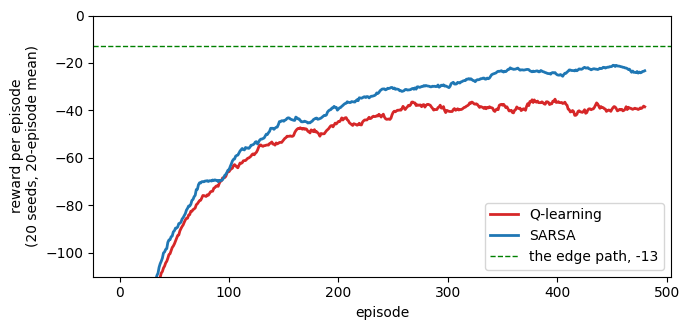

In [16]:
def sarsa(env, episodes=500, alpha=0.1, gamma=0.9, eps=0.1, eps_end=None, q0=0.0, seed=0, max_steps=200):
    """Tabular SARSA: as q_learning, but the target uses the action really taken next."""
    rng = random.Random(seed)
    Q = [[q0] * env.n_actions for _ in range(env.n_states)]
    log = {"reward": np.zeros(episodes), "steps": np.zeros(episodes, dtype=int)}
    for ep in range(episodes):
        e = eps if eps_end is None else eps + (eps_end - eps) * ep / (episodes - 1)
        s = env.reset()
        a = pick(Q[s], e, rng)
        total = 0.0
        for t in range(1, max_steps + 1):
            s2, r, done = env.step(a)
            a2 = pick(Q[s2], e, rng)                                 # choose the next action first...
            target = r if done else r + gamma * Q[s2][a2]            # ...and learn from that one
            Q[s][a] += alpha * (target - Q[s][a])
            total += r
            s, a = s2, a2
            if done: break
        log["reward"][ep], log["steps"][ep] = total, t
    return np.array(Q), log

CLIFF = ["............",
         "............",
         "............",
         "SPPPPPPPPPPG"]
N_CLIFF = 20

def cliff_trial(eps=0.1, eps_end=None, alpha=0.1, quiet=False):
    out = {}
    for name, learner in (("Q-learning", q_learning), ("SARSA", sarsa)):
        curves, last, checks, heights, tables = [], [], [], [], []
        for sd in range(N_CLIFF):
            world = GridWorld(CLIFF, goal_reward=-1.0, pit_reward=-100.0)
            Qs, lg = learner(world, episodes=500, alpha=alpha, gamma=1.0, eps=eps, eps_end=eps_end, seed=sd)
            trace = []
            total, steps, end = run_episode(world, greedy(Qs), max_steps=100, trace=trace)
            curves.append(lg["reward"]); last.append(lg["reward"][-100:].mean()); tables.append(Qs)
            checks.append((int(total), end))
            # how far above the cliff the walk stays while crossing (1 = the row along the edge)
            heights.append(3 - np.mean([c // 12 for c in trace if 1 <= c % 12 <= 10]) if end == "goal" else np.nan)
        out[name] = dict(curves=np.array(curves), last=np.array(last), checks=checks, heights=np.array(heights), tables=tables)
        if not quiet:
            tally = {}
            for c in checks: tally[c] = tally.get(c, 0) + 1
            tally = ", ".join(f"{n} x ({tot}, {end})" for (tot, end), n in sorted(tally.items(), reverse=True))
            print(f"{name:11s} reward while learning, last 100 episodes: {np.mean(last):7.2f}  (std over {N_CLIFF} seeds {np.std(last):.2f})")
            print(f"{'':11s} exploration off, (reward, ending) over the seeds: {tally}")
            print(f"{'':11s} mean height above the cliff of the walks that arrive: {np.nanmean(heights):.2f} rows")
    return out

cliff = cliff_trial()
wins = int((cliff["SARSA"]["last"] > cliff["Q-learning"]["last"]).sum())
print(f"\nseeds in which SARSA collected more than Q-learning while learning: {wins} of {N_CLIFF}")
gaps = cliff["SARSA"]["last"] - cliff["Q-learning"]["last"]
print(f"the gap (SARSA minus Q-learning) per seed runs from {gaps.min():.1f} to {gaps.max():.1f}, mean {gaps.mean():.1f}")

world = GridWorld(CLIFF, goal_reward=-1.0, pit_reward=-100.0)
print("\nQ-learning's policy (seed 0):"); draw_map(world, cliff["Q-learning"]["tables"][0])
print("\nSARSA's policy (seed 0):"); draw_map(world, cliff["SARSA"]["tables"][0])

fig, ax = plt.subplots(figsize=(7, 3.4))
for name, colour in (("Q-learning", "tab:red"), ("SARSA", "tab:blue")):
    ax.plot(smooth(cliff[name]["curves"].mean(axis=0)), color=colour, lw=2, label=name)
ax.axhline(-13, color="green", ls="--", lw=1, label="the edge path, -13")
ax.set_ylim(-110, 0); ax.set_xlabel("episode"); ax.set_ylabel("reward per episode\n(20 seeds, 20-episode mean)"); ax.legend()
plt.tight_layout(); plt.show()

### Why we see this

The classic result appears. **Q-learning learns the edge path**, the shortest one, in every seed, because
it values each cell as if the best move will always follow. But the agent that is doing the learning
explores, and one random step on the edge is a fall. So while it learns, Q-learning keeps falling off the
path its table recommends.

**SARSA learns the value of the behaviour it really has**, slips included. Cells on the edge are worth less
to an agent that sometimes steps at random, so it climbs away from the cliff and walks a longer, safer
line, and it collects more reward during training.

Two details are less tidy than the usual telling, and worth noticing. First, SARSA's safe route here is
one row back from the edge (15 steps) in most seeds, not the far wall that textbook pictures often show:
how far it retreats depends on epsilon and on the learning rate (Trials 6 and 7). Second, the sign of the
gap is the same in every seed but its size is not: it varies by a factor of three. One seed would have
given you the right conclusion here and a poor estimate of how much it matters.

Neither is "better". Q-learning learns the policy you would want **after** exploration is switched off.
SARSA learns the policy that is safe **while** it is still on. If falls during learning are free (a
simulator), take the first. If they cost something real, the second is the honest one.

One more run: let epsilon fade from 0.1 to 0 over the 500 episodes.

**Predict before you run:** as exploration fades, does SARSA's advantage during training stay?

In [17]:
print("epsilon sliding from 0.1 to 0")
fade = cliff_trial(eps=0.1, eps_end=0.0)
wins = int((fade["SARSA"]["last"] > fade["Q-learning"]["last"]).sum())
print(f"\nseeds in which SARSA collected more than Q-learning over the last 100 episodes: {wins} of {N_CLIFF}")

epsilon sliding from 0.1 to 0


Q-learning  reward while learning, last 100 episodes:  -15.92  (std over 20 seeds 1.53)
            exploration off, (reward, ending) over the seeds: 20 x (-13, goal)
            mean height above the cliff of the walks that arrive: 1.00 rows


SARSA       reward while learning, last 100 episodes:  -15.91  (std over 20 seeds 0.85)
            exploration off, (reward, ending) over the seeds: 20 x (-15, goal)
            mean height above the cliff of the walks that arrive: 1.95 rows

seeds in which SARSA collected more than Q-learning over the last 100 episodes: 10 of 20


### Why we see this

With almost no random steps left, walking near the edge is no longer dangerous, and SARSA's advantage
is gone: over the last hundred episodes the two are level, and each is ahead in about half the seeds.
SARSA's caution was a response to its own exploration. Take the exploration away and there is nothing
left to be cautious about. (Its policy is still the 15-step one: in 500 episodes it has not moved down
to the edge, although with exploration gone that is where its values would lead it in the end.)

---
## Step 15 - Three rewards that teach the wrong thing

The agent does not know what you want. It knows what you pay for. Here are three reward designs, each
with a sensible-sounding reason, each tried on the first maze with ten seeds. The planner gives the exact
best behaviour under each design, so we can tell a design fault from a learning fault.

- **A, a coin for progress.** "Let us encourage the first steps in the right direction": a coin worth +3,
  paid each time the agent steps onto the cell two to the right of the start.
- **B, no hurry.** "Only the cheese matters": no cost per step, and no discount (gamma = 1).
- **C, hurry up.** "Make it fast": every step costs -5. And since falling in the pit already loses the
  cheese, the pit itself costs nothing.

**Predict before you run:** for each design, what will the trained agent do with exploration off?

In [18]:
def judge(world, gamma, label):
    Qx, _ = plan(world, gamma, tol=1e-6) if gamma < 1 else (None, None)
    rows = []
    for sd in SEEDS:
        Qs, lg = q_learning(world, gamma=gamma, seed=sd)
        trace = []
        total, steps, end = run_episode(world, greedy(Qs), max_steps=200, trace=trace)
        coins = sum(1 for i, c in enumerate(trace) if world.cell(c) == "o" and (i == 0 or trace[i - 1] != c))
        rows.append((end, steps, total, coins, lg["reward"][-100:].mean()))
    ends = [r[0] for r in rows]
    tally = ", ".join(f"{ends.count(k)} {k}" for k in ("goal", "pit", "time") if ends.count(k))
    print(f"{label}")
    print(f"   10 trained agents, exploration off, end at: {tally}")
    print(f"   steps per episode: {np.mean([r[1] for r in rows]):.1f} | reward per episode: {np.mean([r[2] for r in rows]):.1f}"
          f" | coins per episode: {np.mean([r[3] for r in rows]):.1f} | reward while learning (last 100): {np.mean([r[4] for r in rows]):.1f}")
    if Qx is not None:
        total, steps, end = run_episode(world, greedy(Qx), max_steps=200)
        print(f"   the exact best behaviour under this reward: ends at {end} after {steps} steps, reward {total:.0f}")
    return rows

print("the first maze as designed: ", end=""); base = judge(GridWorld(MAZE), 0.9, "step -1, cheese +10, pit -10, discount 0.9")
COIN_MAZE = ["......", ".####.", "...P.G", ".#...#", "S.o#.."]
print("\nA: ", end=""); ra = judge(GridWorld(COIN_MAZE, coin_reward=3.0), 0.9, "a coin worth +3 on the way")
print("\nA': ", end=""); ra2 = judge(GridWorld(COIN_MAZE, coin_reward=2.0), 0.9, "the same coin, worth +2")
lazy = GridWorld(MAZE, step_reward=0.0)
print("\nB: ", end=""); rb = judge(lazy, 1.0, "no step cost, discount 1")
Qb_exact, _ = plan(lazy, 1.0)
free = [s for s in range(lazy.n_states) if lazy.cell(s) not in "#GPc"]
print(f"   the exact table: {int((Qb_exact[free] == 10).sum())} of {4 * len(free)} entries are exactly 10 (the other "
      f"{int((Qb_exact[free] != 10).sum())} step into the pit)")
for n in (500, 5000):
    Qb, _ = q_learning(lazy, gamma=1.0, episodes=n, seed=0)
    print(f"   learnt table after {n:5,d} episodes, start cell (up, right, down, left): {Qb[lazy.start].round(2)}")
print("\nC: ", end=""); rc = judge(GridWorld(MAZE, step_reward=-5.0, pit_reward=0.0), 0.9, "step -5, pit 0")

# the coin loop against the honest route, by hand, from the cell left of the coin
g = 0.9
loop = (2 - g * 1) / (1 - g * g)             # +2 for stepping on (3 - 1), -1 for stepping off, for ever
print(f"\nby hand, from the cell beside the coin: stepping on and off for ever is worth {loop:.2f};")
print(f"with a coin of +2 it is worth {(1 - g) / (1 - g * g):.2f}. The honest route from the same cell is worth "
      f"{plan(GridWorld(MAZE), 0.9)[0][25].max():.2f}.")

the first maze as designed: step -1, cheese +10, pit -10, discount 0.9
   10 trained agents, exploration off, end at: 10 goal
   steps per episode: 7.0 | reward per episode: 4.0 | coins per episode: 0.0 | reward while learning (last 100): 2.2
   the exact best behaviour under this reward: ends at goal after 7 steps, reward 4

A: 

a coin worth +3 on the way
   10 trained agents, exploration off, end at: 10 time
   steps per episode: 200.0 | reward per episode: 100.0 | coins per episode: 100.0 | reward while learning (last 100): 71.8
   the exact best behaviour under this reward: ends at time after 200 steps, reward 100

A': 

the same coin, worth +2
   10 trained agents, exploration off, end at: 10 time
   steps per episode: 200.0 | reward per episode: 0.0 | coins per episode: 100.0 | reward while learning (last 100): -15.6
   the exact best behaviour under this reward: ends at goal after 7 steps, reward 6

B: no step cost, discount 1
   10 trained agents, exploration off, end at: 10 goal
   steps per episode: 7.4 | reward per episode: 10.0 | coins per episode: 0.0 | reward while learning (last 100): 9.1
   the exact table: 81 of 84 entries are exactly 10 (the other 3 step into the pit)
   learnt table after   500 episodes, start cell (up, right, down, left): [ 2.93 10.    7.31  7.77]
   learnt table after 5,000 episodes, start cell (up, right, down, left): [10. 10. 10. 10.]

C: step -5, pit 0
   10 trained agents, exploration off, end at: 10 pit
   steps per episode: 5.0 | reward per episode: -20.0 | coins per episode: 0.0 | reward while learning (last 100): -23.0
   the exact best behaviour under this rew

### Why we see this

**A.** The agent found that stepping on and off the coin pays for ever, and that for ever is worth more
than one lump of cheese (5.79 against 1.81, from the cell beside the coin). It never finishes the task,
and it collects far more reward per episode than the honest agent ever could. Nothing went wrong with
the learning: the planner confirms that farming the coin *is* the best behaviour under that reward.

**A'.** Shrink the coin to +2 and farming is no longer the best behaviour: the planner picks up the coin
once and walks on to the cheese. The learners farm it anyway. The loop is close, it is the first thing
that pays, and they never find out what lies beyond it. It is Step 12's crumb again. So a tempting
reward on the way can wreck the task twice over: by being worth too much, or only by being found first.

**B.** With no step cost and no discount, a path of 7 steps and a path of 70 both return exactly +10. In
the exact table every move that does not step into the pit is worth 10, walking into a wall included.
The reward said "arrive". It never said "soon". Our learners did arrive quickly after 500 episodes, and
it is worth seeing why: values spread outwards from the cheese, so the entries nearest to it fill up
first and the half-learnt table happens to slope the right way. Train ten times longer and the slope is
gone: all four entries at the start read 10, and which way the agent goes is decided by the last decimal
place. The fault is in the reward, and unfinished learning was hiding it.

**C.** When every step hurts and the pit is free, the pit is the quickest way to stop the pain. The agent
did what the numbers said.

In all three cases, read the last column the way a busy manager would: reward went up, or the agent
"converged". **A rising reward curve tells you the agent is getting better at the reward. Watch what it
does.**

---
## Step 16 - Why the table stops here

Our table has a row for every state. That works because the maze has 30 of them. Count the rows a table
would need elsewhere. (For board games these are upper bounds: every square in every possible condition,
legal or not.)

**Predict before you run:** a small game screen of 84 by 84 pixels, each one of 256 grey levels. How many
digits long is the number of different screens?

In [19]:
import math
print(f"{'world':44s} {'states (rows of the table)':>30s}")
print(f"{'this maze, 5 x 6':44s} {30:>30,d}")
print(f"{'the cliff, 4 x 12':44s} {48:>30,d}")
print(f"{'a 100 x 100 grid':44s} {100 * 100:>30,d}")
print(f"{'noughts and crosses, 3^9 (upper bound)':44s} {3 ** 9:>30,d}")
print(f"{'draughts-sized board, 5^32 (upper bound)':44s} {'about 10^' + str(round(32 * math.log10(5))):>30s}")
print(f"{'Go, 3^361 (upper bound)':44s} {'about 10^' + str(round(361 * math.log10(3))):>30s}")
pixels = 84 * 84
print(f"{'an 84 x 84 screen, 256 grey levels':44s} {'about 10^' + f'{pixels * math.log10(256):,.0f}':>30s}")
print(f"\n84 x 84 = {pixels:,} pixels; 256^{pixels:,} has {math.floor(pixels * math.log10(256)) + 1:,} digits")
print("a robot arm with 6 joint angles, each a real number: no finite table at all")
print(f"\nTotal run time of this notebook: {time.time() - T_START:.0f} s")

world                                            states (rows of the table)
this maze, 5 x 6                                                         30
the cliff, 4 x 12                                                        48
a 100 x 100 grid                                                     10,000
noughts and crosses, 3^9 (upper bound)                               19,683
draughts-sized board, 5^32 (upper bound)                        about 10^22
Go, 3^361 (upper bound)                                        about 10^172
an 84 x 84 screen, 256 grey levels                          about 10^16,993

84 x 84 = 7,056 pixels; 256^7,056 has 16,993 digits
a robot arm with 6 joint angles, each a real number: no finite table at all

Total run time of this notebook: 15 s


### Why we see this

The table has two weaknesses and they are the same weakness. It needs a row for every state, and it
learns nothing about a state from having visited the one next door: Step 9 showed a table that was exact
on the route and wrong a few cells away from it. A table does not generalise.

The cure is to replace the table with a function that takes a state and returns a value for each action,
and that gives similar answers for similar states. A neural network is such a function. Chapter 58 makes
the swap, keeps `reset()` and `step(action)` exactly as they are here, and then spends most of its pages
on what breaks.

---
## Trials: change one thing at a time

Each trial changes one number or one line. Write your prediction first.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 2: `GridWorld(MAZE, slip=0.2)`, then re-run Steps 7 to 9 | Does the best route change? Look at the cell two above the start in the planner's policy. What happens to the value at the start? | |
| 2 | Step 2: `pit_reward=-100.0` with `slip=0.2` | The pit is now ten times worse and the floor is icy. Does the agent still take the short route past it? | |
| 3 | Step 7: `q_learning(env, episodes=50)` over the ten seeds | After only 50 episodes, how many of ten seeds give the best route with exploration off? | |
| 4 | Step 11: `step_reward=0.0` in the world, `eps=0.0` | Zeros are no longer optimistic. Count the seeds whose route is longer than 7 steps. | |
| 5 | Step 12: `crumb_reward=3.0` | At which discounts does the crumb win now? Work it out from `-1 + g x 3` before running. | |
| 6 | Step 14: `cliff_trial(eps=0.3)` | More exploration. Does the gap between the two during training grow or shrink? What happens to SARSA's route? | |
| 7 | Step 14: `cliff_trial(alpha=0.5)` (the setting most textbooks use) | A bolder learning rate. Does SARSA walk higher? Read its table with exploration off: does the policy still arrive in every seed? | |
| 8 | Step 15, design C: `pit_reward=-10.0` | The pit hurts again but steps still cost -5. Pit or cheese? Compute both returns at a discount of 0.9 first. | |

## Exercises

1. **Expected SARSA.** Change SARSA's target to use the *average* of the next state's entries under the
   epsilon-greedy policy (0.9 weight on the best, plus 0.1 spread evenly). Run it on the cliff. Is its
   training reward steadier than SARSA's? Which route does it learn?
2. **A fairer coin.** Change the world so that the coin in Step 15 pays only the first time it is stepped
   on in an episode. The state is no longer only the cell: what must be added to it for the table to work,
   and how many rows does the table have now?
3. **Count-based curiosity.** Keep a table of how often each state-action pair has been tried, and add a
   bonus of `1 / sqrt(count + 1)` to the reward. With `eps=0` and a table starting at -20, does the agent
   of Step 11 now find the cheese?
4. **Monte Carlo.** Instead of updating after every step, wait until the episode ends and move each
   visited entry towards the return that actually followed it. Compare its learning curve with Step 10's
   in the quiet maze and in the icy one. Which method is noisier, and why?
5. **A bigger maze.** Write a 10 by 10 layout of your own with two pits. How many episodes does the agent
   need now? Plot episodes-to-learn against the number of cells for three sizes and extend the line to a
   100 by 100 grid.
6. **Three seeds, three stories.** Re-run Step 13's icy world with `alpha=0.1` and print the policy reward
   of each seed. Pick the best and the worst. If those two were "method A" and "method B" in a report,
   what would the report have concluded?

## Cheat sheet

| Idea | One line |
|---|---|
| The loop | `s = env.reset()`; then `a = policy(s)`; `s, r, done = env.step(a)`; repeat until `done` |
| Reward | a score for the move just made; not a label |
| Return | the rewards from now on, each multiplied by `gamma ** k` for a delay of `k` steps |
| Discount | patience; sees about `1 / (1 - gamma)` steps ahead (0.9: 10 steps; 0.99: 100) |
| Policy | what to do in each state: `argmax(Q[s])` |
| Value | how good a state is under good behaviour: `max(Q[s])` |
| Bellman idea | value here = reward for the next step + gamma x value of where I land |
| Q-learning | `Q[s, a] += alpha * (r + gamma * max(Q[s2]) - Q[s, a])`; off-policy |
| SARSA | `Q[s, a] += alpha * (r + gamma * Q[s2, a2] - Q[s, a])`; on-policy |
| Surprise | the bracket above: the temporal-difference error |
| Epsilon-greedy | random action with probability epsilon, otherwise the best known |
| Optimistic start | begin the table above any return it could really get: untried moves look good |
| Exploration off | set epsilon to 0 before you measure a policy; report training reward separately |
| End of episode | `target = r` (no next state); a time limit is not an end |
| Seeds | several, with the spread; one curve is one story |
| Model-based | given the rules, plan (value iteration); model-free learns from experience alone |